# Airbnb Pricing, Location and Listing Characteristics Investigation
**AnalystLab Africa Experience Lab · Week 1 · Track B: Data Science**

| Item | Detail |
|---|---|
| Intern | *Solomon Buba Tarfa* |
| Track | B: Data Science |
| Tools | Python, pandas, NumPy, SciPy, Matplotlib, Seaborn, Jupyter |
| Inputs | `Listings.csv` (279,712 × 33), `Reviews.csv` (5,373,143 × 4), two data dictionaries |
| Outputs | Tables in `outputs/`, figures in `outputs/figures/` |

## Contents
1. Research problem and objectives (Task 1)
2. Setup and configuration
3. Data loading and inspection (Task 2)
4. Data preparation and cleaning
5. Data-quality summary
6. Exploratory data analysis, 8 visualisations (Task 2)
7. Hypothesis testing, H1–H4 (Task 3)
8. Limitations (Task 4)
9. Findings and recommendations (Task 5)
10. Reproducibility record

## 1. Research problem and objectives

### 1.1 Primary research problem
**How is advertised listing price associated with room type and accommodation capacity (accommodates, bedrooms) within each of the 10 Airbnb city markets, analysed in each city's own local currency?**

### 1.2 Supporting research questions
- **SRQ1:** Do host response indicators (response rate) differ across cities?
- **SRQ2:** Is review activity (number of review records per listing) associated with the listing-level aggregate review rating?

### 1.3 Why it matters
Hosts, platform analysts and market researchers need to know which listing attributes are linked to higher advertised prices, and whether those links are consistent across markets. Without this, price comparisons mix room types, sizes and cities that are not comparable.

### 1.4 Variables required
| Role | Variable | Source |
|---|---|---|
| Outcome | `price` (advertised, local currency) | Listings |
| Predictors | `room_type`, `accommodates`, `bedrooms` | Listings |
| Grouping | `city` | Listings |
| Host indicator | `host_response_rate` | Listings |
| Review activity | review records per listing (`review_count`) | Reviews (aggregated) |
| Review rating | `review_scores_rating` | Listings |

### 1.5 Expected analytical outcome
City-level evidence on (a) whether price differs by room type, (b) the direction and strength of the capacity–price association, (c) cross-city differences in host responsiveness, and (d) whether review volume relates to rating. Each result is reported with an effect size, not only a p-value.

### 1.6 Limitations of the data (summary; detailed in Section 8)
- Prices are **advertised**, in **unlabelled local currencies**, so raw prices are never compared across cities.
- No bookings, occupancy or revenue data exist; no review text exists.
- Review counts measure **review activity**, not satisfaction.
- Results show **association, not causation**.

## 2. Setup and configuration

In [1]:
import os  # build folder paths and create output folders
import platform  # record the Python version for reproducibility
import warnings  # control noisy library warnings

import numpy as np  # numerical operations
import pandas as pd  # tabular data handling
import matplotlib.pyplot as plt  # plotting engine
import seaborn as sns  # statistical plotting on top of matplotlib
import scipy  # imported to record its version
from scipy import stats  # statistical tests (Kruskal-Wallis, Spearman, Levene, Shapiro)

warnings.filterwarnings("ignore", category=FutureWarning)  # hide harmless pandas/seaborn future warnings

In [2]:
#RAW_DIR = "data/raw"  # folder that holds the ORIGINAL, untouched CSV files
RAW_DIR = r"C:\Users\Tarfa_Jr\Downloads"  # r"..." raw string so Windows backslashes are not treated as escapes
OUT_DIR = "outputs"  # folder for tables produced by this notebook
FIG_DIR = os.path.join(OUT_DIR, "figures")  # folder for saved charts
LISTINGS_FILE = "Listings.csv"  # exact name found by the search
REVIEWS_FILE = "Reviews.csv"   # name of the listings file
SEED = 42  # fixed random seed so sampled steps are reproducible
ALPHA = 0.05  # significance level used for every test
MIN_GROUP_N = 30  # smallest group size allowed in a test (avoids unstable estimates)
EXTREME_IQR_K = 3.0  # Tukey fence multiplier used to FLAG extreme prices (flag, not delete)

os.makedirs(OUT_DIR, exist_ok=True)  # create the outputs folder if missing
os.makedirs(FIG_DIR, exist_ok=True)  # create the figures folder if missing
rng = np.random.default_rng(SEED)  # random generator used wherever sampling is needed
sns.set_theme(style="whitegrid", context="notebook")  # consistent, readable plot style
pd.set_option("display.max_columns", 60)  # show all columns when printing tables
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")  # readable number format

## 3. Data loading and inspection (Task 2)

**Privacy rule:** the notebook never prints or exports host names, listing names or `reviewer_id`. `reviewer_id` is used only for a duplicate check and then dropped.

In [3]:
listings_path = os.path.join(RAW_DIR, LISTINGS_FILE)  # full path to the listings file
reviews_path = os.path.join(RAW_DIR, REVIEWS_FILE)  # full path to the reviews file
assert os.path.exists(listings_path), f"Missing {listings_path}. Place the original file in {RAW_DIR}/"  # fail early with a clear message
assert os.path.exists(reviews_path), f"Missing {reviews_path}. Place the original file in {RAW_DIR}/"  # fail early with a clear message

try:  # first try the standard UTF-8 encoding
    listings_raw = pd.read_csv(listings_path, low_memory=False)  # load listings (about 280k rows, fits in memory)
except UnicodeDecodeError:  # the supplied Listings.csv contains non-UTF-8 bytes (accented text in listing names)
    listings_raw = pd.read_csv(listings_path, low_memory=False, encoding="latin-1")  # latin-1 reads every byte; text columns we use are unaffected
reviews_raw = pd.read_csv(  # load reviews (about 5.4M rows) using only needed columns to save memory
    reviews_path,
    usecols=["listing_id", "review_id", "date", "reviewer_id"],  # the 4 documented columns
    parse_dates=["date"],  # convert the review date to datetime
)

print("Listings shape:", listings_raw.shape)  # expected (279712, 33)
print("Reviews shape :", reviews_raw.shape)  # expected (5373143, 4)

Listings shape: (279712, 33)
Reviews shape : (5373143, 4)


In [4]:
def resolve(df, candidates, required=True):
    # return the first candidate column name that exists in df
    for name in candidates:  # try each acceptable spelling in order
        if name in df.columns:  # column found
            return name  # use it
    if required:  # a mandatory column is missing
        raise KeyError(f"None of {candidates} found. Check the data dictionary. Available: {list(df.columns)}")
    return None  # optional column not present


COLMAP = {  # map standard analysis names -> actual column names in Listings.csv
    "listing_id": resolve(listings_raw, ["listing_id", "id"]),  # primary key
    "city": resolve(listings_raw, ["city"]),  # market
    "room_type": resolve(listings_raw, ["room_type"]),  # room category
    "property_type": resolve(listings_raw, ["property_type"]),  # property category
    "price_raw": resolve(listings_raw, ["price"]),  # advertised price (local currency)
    "accommodates": resolve(listings_raw, ["accommodates"]),  # guest capacity
    "bedrooms": resolve(listings_raw, ["bedrooms"]),  # number of bedrooms
    "rating": resolve(listings_raw, ["review_scores_rating", "review_score_rating"]),  # overall rating
    "response_rate": resolve(listings_raw, ["host_response_rate"]),  # host response indicator
    "acceptance_rate": resolve(listings_raw, ["host_acceptance_rate"], required=False),  # optional
    "district": resolve(listings_raw, ["district", "neighbourhood_group"], required=False),  # optional
    "neighbourhood": resolve(listings_raw, ["neighbourhood", "neighborhood"], required=False),  # optional
}
COLMAP = {k: v for k, v in COLMAP.items() if v is not None}  # keep only the columns that exist
print(COLMAP)  # show the mapping so the reviewer can verify it against the dictionary

{'listing_id': 'listing_id', 'city': 'city', 'room_type': 'room_type', 'property_type': 'property_type', 'price_raw': 'price', 'accommodates': 'accommodates', 'bedrooms': 'bedrooms', 'rating': 'review_scores_rating', 'response_rate': 'host_response_rate', 'acceptance_rate': 'host_acceptance_rate', 'district': 'district', 'neighbourhood': 'neighbourhood'}


In [5]:
keep_cols = list(COLMAP.values())  # only the columns needed (also keeps identifying columns out of memory)
listings = listings_raw[keep_cols].rename(columns={v: k for k, v in COLMAP.items()}).copy()  # standard names, work on a copy
listings.info()  # data types, non-null counts and memory use

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 279712 entries, 0 to 279711
Data columns (total 12 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   listing_id       279712 non-null  int64  
 1   city             279712 non-null  object 
 2   room_type        279712 non-null  object 
 3   property_type    279712 non-null  object 
 4   price_raw        279712 non-null  int64  
 5   accommodates     279712 non-null  int64  
 6   bedrooms         250277 non-null  float64
 7   rating           188307 non-null  float64
 8   response_rate    150930 non-null  float64
 9   acceptance_rate  166625 non-null  float64
 10  district         37012 non-null   object 
 11  neighbourhood    279712 non-null  object 
dtypes: float64(4), int64(3), object(5)
memory usage: 25.6+ MB


In [6]:
# ---- Primary key validation (Listings) ----
n_listings = len(listings)  # total listing records
n_unique_ids = listings["listing_id"].nunique()  # distinct listing ids
print(f"listing_id unique? {listings['listing_id'].is_unique}  ({n_unique_ids:,} unique of {n_listings:,})")  # PK check
print("Null listing_id:", listings["listing_id"].isna().sum())  # a PK must never be null
print("Fully duplicated listing rows:", listings.duplicated().sum())  # exact duplicate records

# ---- Foreign key validation (Reviews -> Listings) ----
orphan = ~reviews_raw["listing_id"].isin(listings["listing_id"])  # reviews pointing to a missing listing
print("Review rows with no matching listing:", int(orphan.sum()))  # expected 0
listings_with_reviews = listings["listing_id"].isin(reviews_raw["listing_id"]).mean()  # coverage
print(f"Share of listings with at least one review record: {listings_with_reviews:.1%}")  # many will have none

listing_id unique? True  (279,712 unique of 279,712)
Null listing_id: 0
Fully duplicated listing rows: 0
Review rows with no matching listing: 0
Share of listings with at least one review record: 69.2%


In [7]:
# ---- Investigate the repeated review_id values (do NOT delete automatically) ----
dup_mask = reviews_raw["review_id"].duplicated(keep=False)  # mark every row that shares a review_id
dup_rows = reviews_raw[dup_mask].sort_values(["review_id", "listing_id"])  # all rows involved in duplication
n_dup_ids = dup_rows["review_id"].nunique()  # number of distinct repeated ids
print(f"Rows involved in repeated review_id: {len(dup_rows):,}")  # row count
print(f"Distinct repeated review_id values : {n_dup_ids:,}")  # compare with the 160 stated in the brief
print("Surplus rows (rows minus distinct ids):", reviews_raw['review_id'].duplicated().sum())  # extra occurrences

comp_dups = reviews_raw.duplicated(["listing_id", "review_id"]).sum()  # is (listing_id, review_id) unique?
print("Duplicate (listing_id, review_id) pairs:", comp_dups)  # brief says 0
full_dups = reviews_raw.duplicated().sum()  # exact duplicate rows (all 4 columns)
print("Fully identical rows:", full_dups)  # shows if duplicates are true copies

per_id = dup_rows.groupby("review_id").agg(n_rows=("listing_id", "size"), n_listings=("listing_id", "nunique"))  # pattern per id
print("Repeated ids spanning more than one listing:", int((per_id["n_listings"] > 1).sum()))  # same id, different listing
print("Repeated ids inside one listing:", int((per_id["n_listings"] == 1).sum()))  # same id, same listing
dup_rows.drop(columns="reviewer_id").head(10)  # preview WITHOUT the reviewer identifier

Rows involved in repeated review_id: 320
Distinct repeated review_id values : 160
Surplus rows (rows minus distinct ids): 160
Duplicate (listing_id, review_id) pairs: 0
Fully identical rows: 0
Repeated ids spanning more than one listing: 160
Repeated ids inside one listing: 0


,listing_id,review_id,date
4548449,2997346,200088015,2017-10-04
4549014,22219088,200088015,2017-10-04
4430927,2997346,205182329,2017-10-21
4431427,22219088,205182329,2017-10-21
4283655,2997346,223954194,2018-01-02
4284366,22219088,223954194,2018-01-02
4564028,2997346,256197483,2018-04-22
4564678,22219088,256197483,2018-04-22
4403226,466155,256940062,2018-04-24
4403899,22219250,256940062,2018-04-24


**Documented decision on repeated `review_id`:** the pair (`listing_id`, `review_id`) is unique, so each row is a distinct review event on a specific listing. Rows are therefore **retained**. `review_id` alone is never used as a key; review counts are computed per `listing_id` (row counts), which makes the analysis immune to the repeated identifiers. On the supplied file the check shows that all 160 repeated `review_id` values are **reused across different listings** (none repeat within one listing, and no row is an exact copy), so they are reused identifiers rather than duplicated records, and deleting any of them would wrongly remove genuine reviews.

In [8]:
reviews = reviews_raw.drop(columns=["reviewer_id"]).copy()  # drop reviewer identifier: not needed, protects privacy
print("Review date range:", reviews["date"].min().date(), "->", reviews["date"].max().date())  # time coverage
print("Null review dates:", int(reviews["date"].isna().sum()))  # parsing problems would appear here

Review date range: 2008-11-16 -> 2021-03-01
Null review dates: 0


## 4. Data preparation and cleaning

Every transformation below is logged in `cleaning_log`, which is exported as part of the data-quality summary.

In [9]:
cleaning_log = []  # list of dictionaries: one entry per cleaning decision


def log(step, detail, rows_affected):
    # record a cleaning decision so it can be audited later
    cleaning_log.append({"step": step, "detail": detail, "rows_affected": int(rows_affected)})  # append one entry


def to_number(series):
    # convert a column to numbers, stripping currency symbols and thousands separators if it is text
    if pd.api.types.is_numeric_dtype(series):  # already numeric: nothing to strip
        return series.astype(float)  # return as float
    cleaned = series.astype(str).str.replace(r"[^0-9.\-]", "", regex=True)  # keep digits, dot and minus only
    return pd.to_numeric(cleaned.replace("", np.nan), errors="coerce")  # empty strings become NaN

In [10]:
# ---- Price: parse, validate, flag extremes ----
listings["price_local"] = to_number(listings["price_raw"])  # numeric advertised price in LOCAL currency
log("price parsing", "converted price text to numeric (symbols and commas removed)", listings["price_raw"].notna().sum())  # log it

n_missing_price = listings["price_local"].isna().sum()  # missing / unparseable prices
n_nonpositive = (listings["price_local"] <= 0).sum()  # zero or negative prices are invalid for a nightly price
print(f"Missing price: {n_missing_price:,} | Non-positive price: {n_nonpositive:,}")  # report counts
log("invalid price", "price missing or <= 0 excluded from price analyses (kept in listing counts)", n_missing_price + n_nonpositive)  # log it

listings["price_valid"] = listings["price_local"] > 0  # True only for usable prices
listings["log_price"] = np.where(listings["price_valid"], np.log(listings["price_local"].where(listings["price_valid"])), np.nan)  # log scale tames right skew

Missing price: 0 | Non-positive price: 113


In [11]:
# ---- Flag extreme prices per city (Tukey fences on log price). FLAG ONLY, do not delete. ----
def flag_extreme(group):
    q1, q3 = group.quantile(0.25), group.quantile(0.75)  # quartiles of log price within the city
    iqr = q3 - q1  # inter-quartile range
    return (group < q1 - EXTREME_IQR_K * iqr) | (group > q3 + EXTREME_IQR_K * iqr)  # outside the outer fences


listings["extreme_price"] = False  # default: not extreme
valid_idx = listings.index[listings["price_valid"]]  # rows with usable prices
flags = listings.loc[valid_idx].groupby("city")["log_price"].transform(flag_extreme)  # per-city extreme flag
listings.loc[valid_idx, "extreme_price"] = flags.values  # write the flags back
print("Extreme-price listings flagged:", int(listings["extreme_price"].sum()))  # how many are flagged
log("extreme price flag", f"flagged with {EXTREME_IQR_K}x IQR fences on log price within city; retained (rank-based tests are robust; sensitivity run in H1/H2)", listings["extreme_price"].sum())  # log it

Extreme-price listings flagged: 641


In [12]:
# ---- Host response / acceptance rates: convert "95%" text to a 0-100 number ----
for col in ["response_rate", "acceptance_rate"]:  # both host indicators
    if col in listings.columns:  # acceptance_rate is optional
        listings[col] = to_number(listings[col])  # numeric conversion
        if listings[col].max(skipna=True) <= 1.0:  # rate stored as a fraction 0-1
            listings[col] = listings[col] * 100  # convert to percentage points
        log(f"{col} parsing", "converted to numeric percentage (0-100)", listings[col].notna().sum())  # log it

# ---- Numeric structure columns ----
for col in ["accommodates", "bedrooms", "rating"]:  # capacity, bedrooms, overall rating
    listings[col] = pd.to_numeric(listings[col], errors="coerce")  # force numeric, bad values become NaN

# ---- Text categories: trim whitespace and standardise case of labels ----
for col in ["city", "room_type", "property_type"]:  # categorical fields
    listings[col] = listings[col].astype("string").str.strip()  # remove stray spaces
log("category trimming", "stripped whitespace in city/room_type/property_type", len(listings))  # log it
print(listings["city"].nunique(), "cities:", sorted(listings["city"].dropna().unique()))  # confirm 10 cities

10 cities: ['Bangkok', 'Cape Town', 'Hong Kong', 'Istanbul', 'Mexico City', 'New York', 'Paris', 'Rio de Janeiro', 'Rome', 'Sydney']


In [13]:
# ---- Attach review activity (aggregated from 5.4M review rows) ----
review_counts = reviews.groupby("listing_id").size().rename("review_count")  # number of review RECORDS per listing
first_review = reviews.groupby("listing_id")["date"].min().rename("first_review_date")  # earliest review date
last_review = reviews.groupby("listing_id")["date"].max().rename("last_review_date")  # latest review date

listings = listings.merge(review_counts, left_on="listing_id", right_index=True, how="left")  # left join keeps all listings
listings = listings.merge(first_review, left_on="listing_id", right_index=True, how="left")  # add first date
listings = listings.merge(last_review, left_on="listing_id", right_index=True, how="left")  # add last date
listings["has_review_record"] = listings["review_count"].notna()  # NaN means no record in the EXTRACT (not proof of zero reviews)

assert len(listings) == n_listings, "Join changed the listing row count: investigate"  # one-to-many join must not multiply listings
assert int(listings["review_count"].sum()) == len(reviews), "Review totals do not reconcile"  # independent reconciliation check
print("Reconciliation OK: sum of per-listing review counts equals total review rows =", f"{len(reviews):,}")  # evidence for validation
log("review aggregation", "review rows counted per listing_id; listings without records left as NaN", listings["has_review_record"].sum())  # log it

Reconciliation OK: sum of per-listing review counts equals total review rows = 5,373,143


In [14]:
analysis = listings[listings["price_valid"]].copy()  # price-analysis dataset: valid positive prices only
print(f"Listings total: {len(listings):,} | usable for price analysis: {len(analysis):,} ({len(analysis)/len(listings):.1%})")  # summary
print("\nListings per city in the analysis set (note UNEQUAL sizes):")  # unequal sizes affect power
print(analysis["city"].value_counts().to_string())  # per-city counts

Listings total: 279,712 | usable for price analysis: 279,599 (100.0%)

Listings per city in the analysis set (note UNEQUAL sizes):
city
Paris             64628
New York          36984
Sydney            33630
Rome              27641
Rio de Janeiro    26608
Istanbul          24517
Mexico City       20058
Bangkok           19360
Cape Town         19086
Hong Kong          7087


## 5. Data-quality summary

In [15]:
quality = pd.DataFrame({  # one row per analysed column
    "dtype": listings.dtypes.astype(str),  # data type after cleaning
    "n_missing": listings.isna().sum(),  # count of missing values
    "pct_missing": listings.isna().mean() * 100,  # percent missing
    "n_unique": listings.nunique(),  # distinct values
}).sort_values("pct_missing", ascending=False)  # most incomplete first
quality.to_csv(os.path.join(OUT_DIR, "data_quality_summary.csv"))  # save for submission
pd.DataFrame(cleaning_log).to_csv(os.path.join(OUT_DIR, "cleaning_log.csv"), index=False)  # save the audit trail
display(quality)  # show the table
display(pd.DataFrame(cleaning_log))  # show the cleaning decisions

,dtype,n_missing,pct_missing,n_unique
district,object,242700,86.7678,5
response_rate,float64,128782,46.0409,91
acceptance_rate,float64,113087,40.4298,101
rating,float64,91405,32.6783,63
last_review_date,datetime64[ns],86156,30.8017,2709
first_review_date,datetime64[ns],86156,30.8017,3745
review_count,float64,86156,30.8017,548
bedrooms,float64,29435,10.5233,39
log_price,float64,113,0.0404,5193
price_local,float64,0,0.0000,5194


,step,detail,rows_affected
0,price parsing,converted price text to numeric (symbols and c...,279712
1,invalid price,price missing or <= 0 excluded from price anal...,113
2,extreme price flag,flagged with 3.0x IQR fences on log price with...,641
3,response_rate parsing,converted to numeric percentage (0-100),150930
4,acceptance_rate parsing,converted to numeric percentage (0-100),166625
5,category trimming,stripped whitespace in city/room_type/property...,279712
6,review aggregation,review rows counted per listing_id; listings w...,193556


### Missing-value treatment decisions
| Field | Treatment | Reason |
|---|---|---|
| `price` (missing / ≤ 0) | Excluded from price analyses only | A price cannot be imputed credibly and it is the outcome variable |
| `bedrooms` | **Complete-case** for tests that use it (no imputation) | Imputing would invent structure and bias associations |
| `review_scores_rating` | Complete-case; missing ≠ low rating | Missingness is usually "no reviews yet" |
| `host_response_rate` | Complete-case; missingness reported | Missingness may signal hosts without any response history |
| `district` | Not used as a predictor; reported only | Too incomplete in several cities to compare fairly |
| Review counts | Missing for listings absent from the extract; analysed only where a record exists | Absence from the extract is not proof of zero reviews |

## 6. Exploratory data analysis (Task 2)

> **Currency caution:** price charts are drawn **per city with independent axes**. Price levels are never compared across cities.

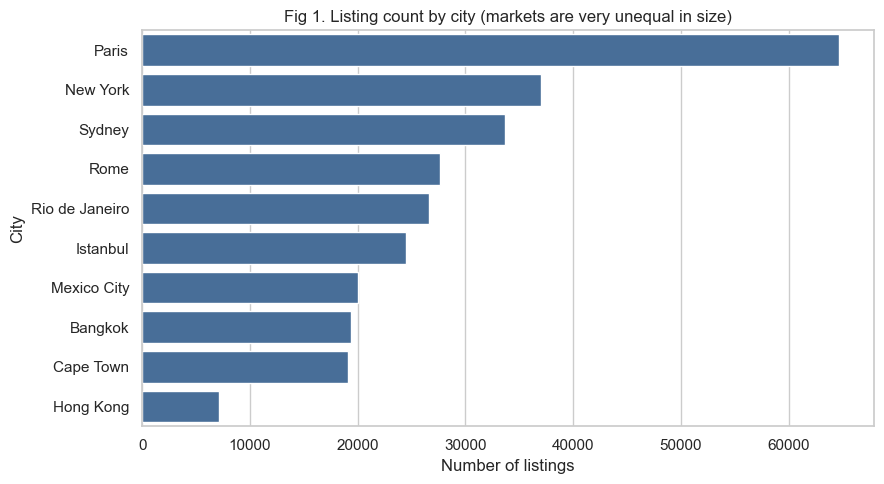

In [16]:
def savefig(name):
    # save the current figure at print quality and show it
    plt.tight_layout()  # avoid overlapping labels
    plt.savefig(os.path.join(FIG_DIR, name), dpi=200, bbox_inches="tight")  # write PNG to disk
    plt.show()  # display in the notebook


# ---- Figure 1: listings per city ----
city_counts = listings["city"].value_counts()  # listing count per city
plt.figure(figsize=(9, 5))  # canvas size
sns.barplot(x=city_counts.values, y=city_counts.index, color="#3b6ea5")  # horizontal bars sorted by size
plt.xlabel("Number of listings")  # axis label
plt.ylabel("City")  # axis label
plt.title("Fig 1. Listing count by city (markets are very unequal in size)")  # title states the key message
savefig("fig1_listings_per_city.png")  # save and show
city_counts.to_csv(os.path.join(OUT_DIR, "listings_per_city.csv"))  # keep the numbers for the report

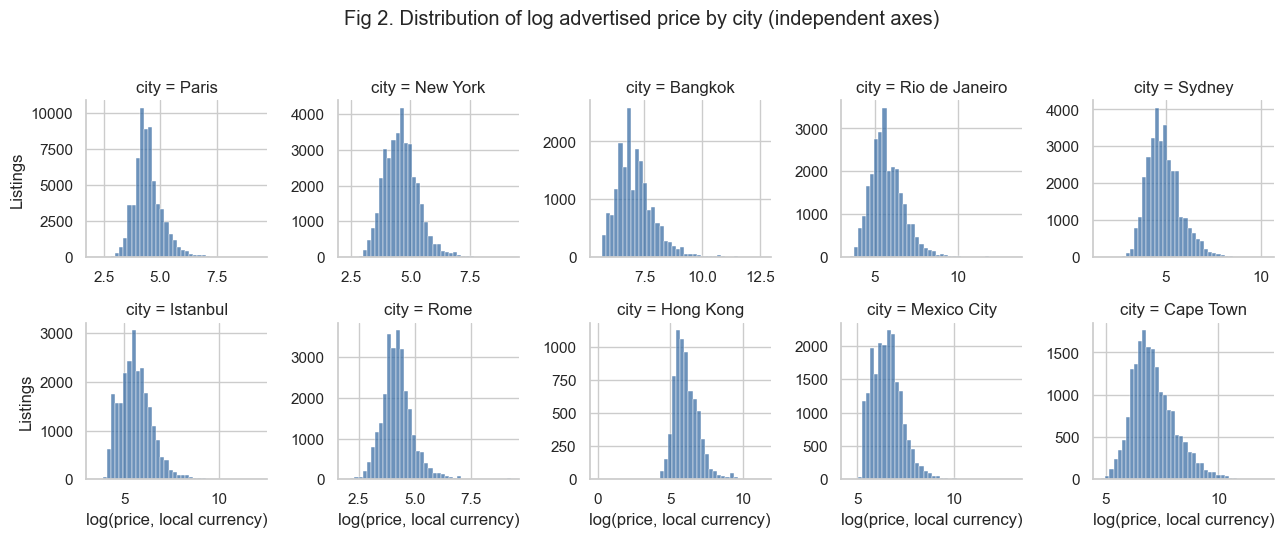

,count,mean,std,min,25%,50%,75%,99%,max
city,,,,,,,,,
Bangkok,"19,360.0000","2,078.3854","6,379.9353",241.0000,700.0000,"1,100.0000","1,900.0000","15,553.3900","300,177.0000"
Cape Town,"19,086.0000","2,405.1203","6,143.1980",122.0000,650.0000,"1,069.0000","2,200.0000","22,018.9000","180,000.0000"
Hong Kong,"7,087.0000",746.1699,"1,938.2368",1.0000,248.0000,386.0000,700.0000,"8,799.0000","83,665.0000"
Istanbul,"24,517.0000",532.6009,"3,318.5525",31.0000,150.0000,252.0000,449.0000,"3,805.8800","179,532.0000"
Mexico City,"20,058.0000","1,149.6541","5,372.9093",100.0000,392.0000,664.0000,"1,124.0000","7,294.7200","499,000.0000"
New York,"36,984.0000",142.9504,275.8173,10.0000,60.0000,99.0000,151.0000,850.0000,"10,000.0000"
Paris,"64,628.0000",113.2049,214.5079,8.0000,59.0000,80.0000,120.0000,600.0000,"12,000.0000"
Rio de Janeiro,"26,608.0000",742.7846,"5,369.5615",33.0000,157.0000,280.0000,550.0000,"5,696.6400","625,216.0000"
Rome,"27,641.0000",105.1305,341.1884,7.0000,45.0000,65.0000,99.0000,600.0000,"10,571.0000"


In [17]:
# ---- Figure 2: price distribution per city (each city on its own axis, local currency) ----
g = sns.FacetGrid(analysis, col="city", col_wrap=5, sharex=False, sharey=False, height=2.6)  # one panel per city
g.map_dataframe(sns.histplot, x="log_price", bins=40, color="#3b6ea5")  # histogram of log price
g.set_axis_labels("log(price, local currency)", "Listings")  # axis labels
g.fig.suptitle("Fig 2. Distribution of log advertised price by city (independent axes)", y=1.03)  # title
savefig("fig2_price_distribution_by_city.png")  # save and show

price_summary = analysis.groupby("city")["price_local"].describe(percentiles=[0.25, 0.5, 0.75, 0.99])  # per-city stats
price_summary.to_csv(os.path.join(OUT_DIR, "price_summary_by_city_local_currency.csv"))  # save (LOCAL currency)
display(price_summary)  # show the table: read row by row, never across rows

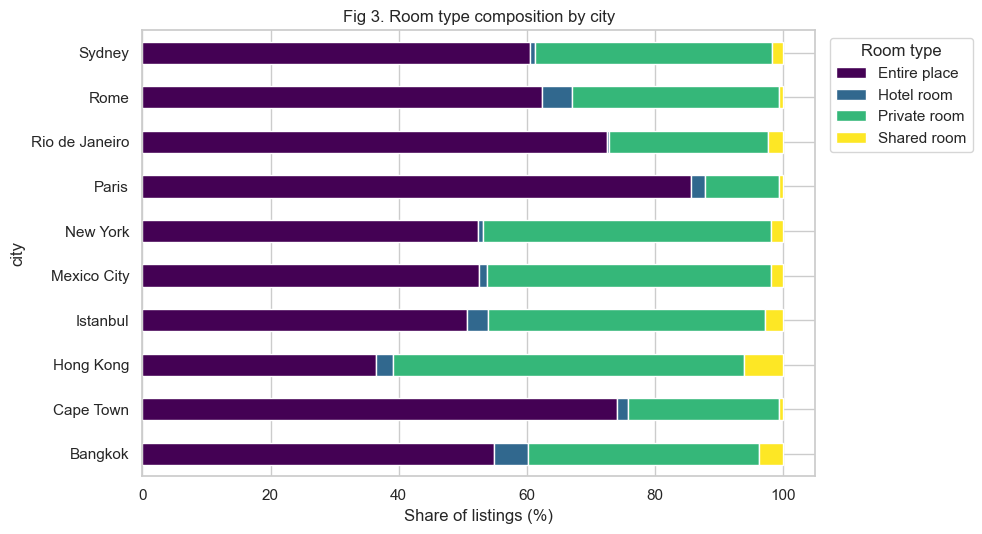

,listings
property_type,
Entire apartment,138989
Private room in apartment,47322
Private room in house,13292
Entire house,13273
Entire condominium,11250
Room in boutique hotel,5771
Entire loft,4587
Private room in condominium,4462
Private room in bed and breakfast,4238


In [18]:
# ---- Figure 3: room type mix by city ----
mix = pd.crosstab(listings["city"], listings["room_type"], normalize="index") * 100  # % of each city's listings
mix.plot(kind="barh", stacked=True, figsize=(10, 5.5), colormap="viridis")  # stacked horizontal bars
plt.xlabel("Share of listings (%)")  # axis label
plt.title("Fig 3. Room type composition by city")  # title
plt.legend(title="Room type", bbox_to_anchor=(1.01, 1), loc="upper left")  # legend outside the plot
savefig("fig3_room_type_mix.png")  # save and show

top_property = listings["property_type"].value_counts().head(10)  # 10 most common property types
top_property.to_csv(os.path.join(OUT_DIR, "top10_property_types.csv"))  # save for the report
display(top_property.to_frame("listings"))  # show the table

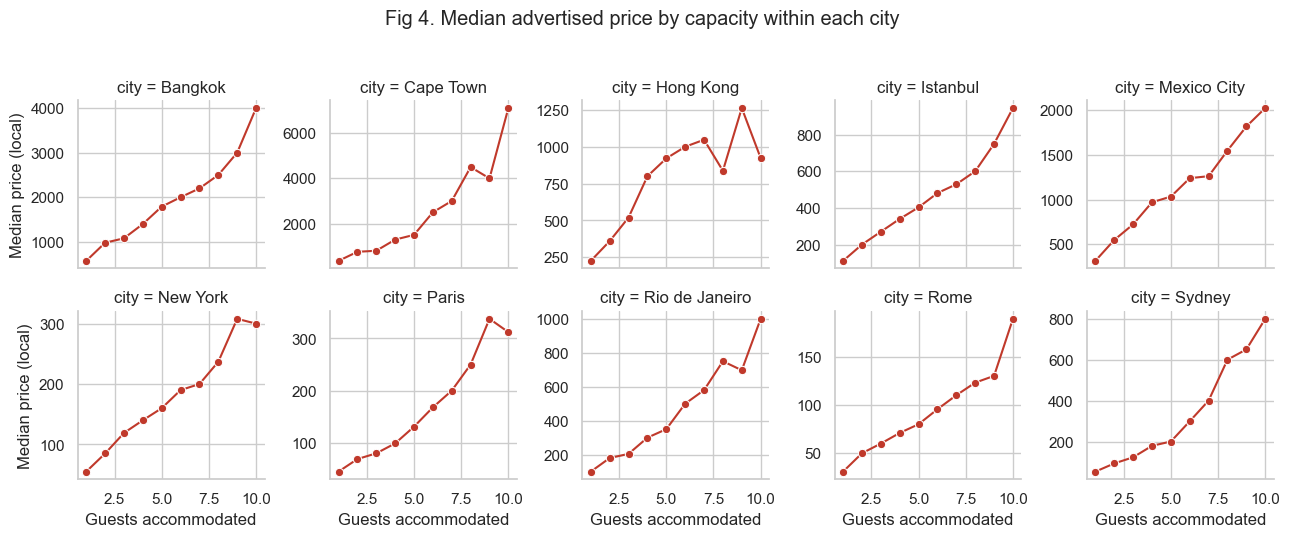

In [19]:
# ---- Figure 4: median price by capacity, per city ----
cap = analysis[analysis["accommodates"].between(1, 10)]  # capacities 1-10 (rare large values are noisy)
cap_med = cap.groupby(["city", "accommodates"])["price_local"].median().reset_index()  # median price per capacity
g = sns.FacetGrid(cap_med, col="city", col_wrap=5, sharex=True, sharey=False, height=2.6)  # independent price axes
g.map_dataframe(sns.lineplot, x="accommodates", y="price_local", marker="o", color="#c0392b")  # median line
g.set_axis_labels("Guests accommodated", "Median price (local)")  # axis labels
g.fig.suptitle("Fig 4. Median advertised price by capacity within each city", y=1.03)  # title
savefig("fig4_median_price_by_capacity.png")  # save and show

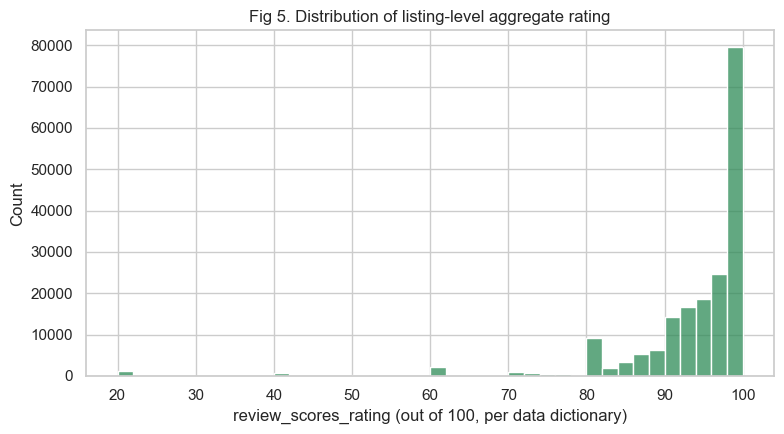

Rating missing: 32.7%


In [20]:
# ---- Figure 5: listing-level rating distribution ----
plt.figure(figsize=(8, 4.5))  # canvas
sns.histplot(listings["rating"].dropna(), bins=40, color="#2e8b57")  # histogram of non-missing ratings
plt.xlabel("review_scores_rating (out of 100, per data dictionary)")  # axis label (scale confirmed by the dictionary)
plt.title("Fig 5. Distribution of listing-level aggregate rating")  # title
savefig("fig5_rating_distribution.png")  # save and show
print("Rating missing:", f"{listings['rating'].isna().mean():.1%}")  # how incomplete the rating field is

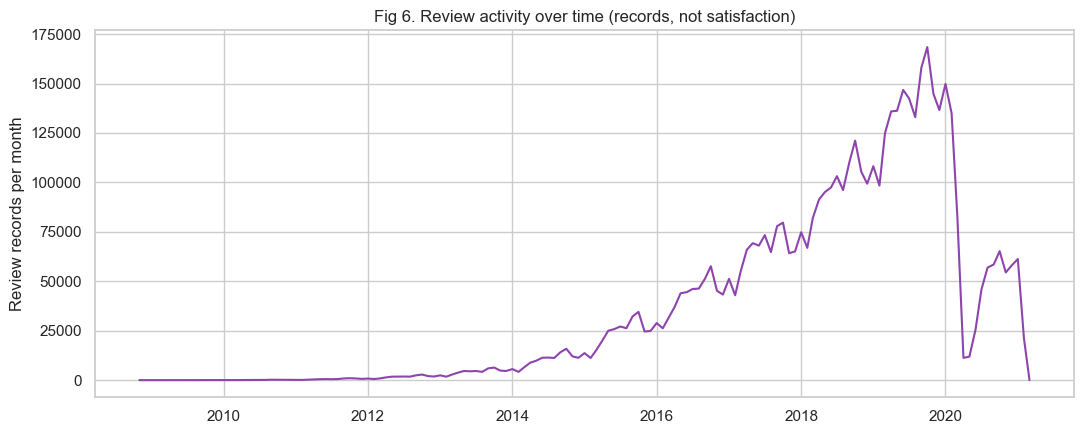

In [21]:
# ---- Figure 6: review activity over time ----
monthly = reviews.groupby(reviews["date"].dt.to_period("M")).size()  # review records per month
monthly.index = monthly.index.to_timestamp()  # convert period index to timestamps for plotting
plt.figure(figsize=(11, 4.5))  # canvas
plt.plot(monthly.index, monthly.values, color="#8e44ad")  # monthly line
plt.ylabel("Review records per month")  # axis label
plt.title("Fig 6. Review activity over time (records, not satisfaction)")  # title
savefig("fig6_reviews_over_time.png")  # save and show
monthly.to_csv(os.path.join(OUT_DIR, "reviews_per_month.csv"), header=["review_records"])  # save the series

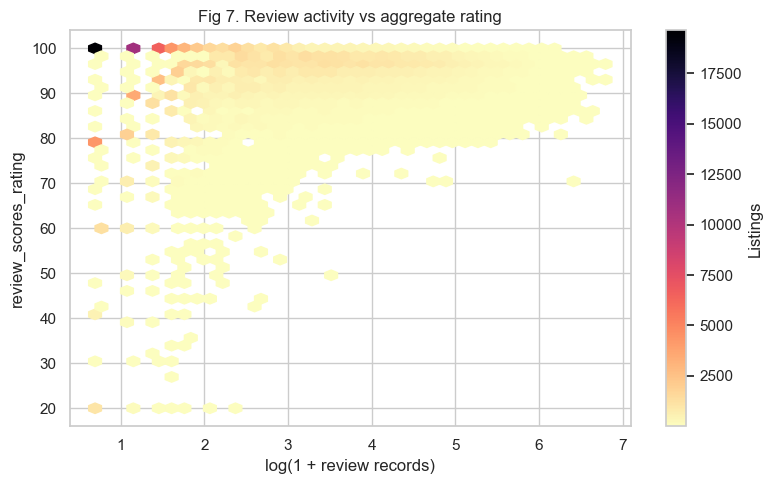

In [22]:
# ---- Figure 7: review count vs rating ----
rv = listings.dropna(subset=["review_count", "rating"])  # listings with both measures
plt.figure(figsize=(8, 5))  # canvas
plt.hexbin(np.log1p(rv["review_count"]), rv["rating"], gridsize=40, cmap="magma_r", mincnt=1)  # density view (avoids overplotting)
plt.colorbar(label="Listings")  # colour scale
plt.xlabel("log(1 + review records)")  # axis label
plt.ylabel("review_scores_rating")  # axis label
plt.title("Fig 7. Review activity vs aggregate rating")  # title
savefig("fig7_reviews_vs_rating.png")  # save and show

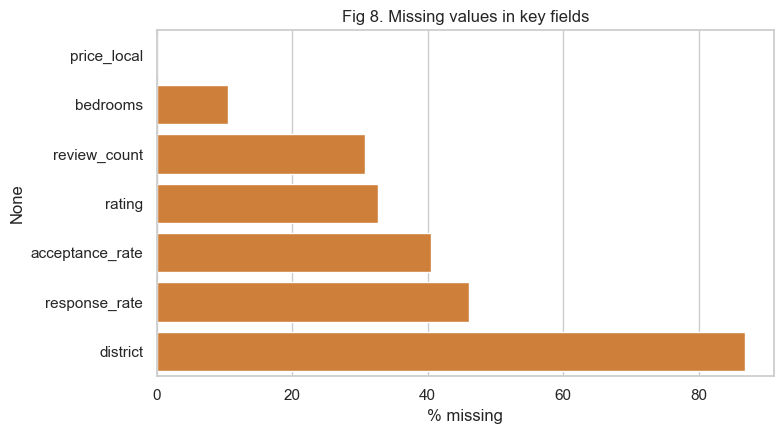

In [23]:
# ---- Figure 8: missingness of key analysis fields ----
miss = listings[["price_local", "bedrooms", "rating", "response_rate", "review_count"] + [c for c in ["district", "acceptance_rate"] if c in listings.columns]]  # fields of interest
miss_pct = miss.isna().mean().sort_values() * 100  # percent missing, sorted
plt.figure(figsize=(8, 4.5))  # canvas
sns.barplot(x=miss_pct.values, y=miss_pct.index, color="#e67e22")  # horizontal bars
plt.xlabel("% missing")  # axis label
plt.title("Fig 8. Missing values in key fields")  # title
savefig("fig8_missingness.png")  # save and show

### What the EDA shows and what it cannot establish
- **Shows:** unequal market sizes, right-skewed prices (so log scale / rank-based methods), room-type composition differing by city, and the extent of missing fields.
- **Cannot establish:** that any attribute *causes* a higher price; actual occupancy or revenue; guest satisfaction (review counts are activity only); or anything about written feedback (no text supplied).

## 7. Hypothesis testing (Task 3)

**Common choices**
- Price is strongly right-skewed, so tests use **rank-based** methods (Kruskal–Wallis, Spearman) on local-currency prices, with log price used only for assumption checks.
- Tests run **within each city** (no cross-currency pooling); the family of 10 city tests per hypothesis is controlled with the **Holm correction**.
- Both **statistical significance** (adjusted p) and **practical significance** (effect size) are reported. With very large samples, tiny effects become "significant".

In [24]:
def holm(pvals):
    # Holm step-down adjustment: controls family-wise error across the 10 city tests
    p = np.asarray(pvals, dtype=float)  # p-values as an array
    order = np.argsort(p)  # smallest first
    m = len(p)  # number of tests in the family
    adjusted = np.empty(m)  # output array
    running = 0.0  # enforces monotonicity of adjusted p-values
    for rank, idx in enumerate(order):  # walk from smallest to largest p
        running = max(running, (m - rank) * p[idx])  # scale and keep non-decreasing
        adjusted[idx] = min(1.0, running)  # cap at 1
    return adjusted  # adjusted p-values in original order


def fisher_ci(rho, n):
    # approximate 95% CI for a Spearman correlation (Fisher z with Bonett-Wright variance)
    z = np.arctanh(rho)  # transform to z scale
    se = np.sqrt(1.06 / (n - 3))  # standard error for Spearman
    return float(np.tanh(z - 1.96 * se)), float(np.tanh(z + 1.96 * se))  # back-transform bounds


def spearman_strength(r):
    # plain-language label for practical significance (Cohen-style thresholds)
    a = abs(r)  # magnitude only
    return "negligible" if a < 0.1 else "weak" if a < 0.3 else "moderate" if a < 0.5 else "strong"  # label

### H1. Advertised price differs across room types within a city
- **H0:** the distribution of advertised price is the same for all room types in the city.
- **H1:** at least one room type has a different price distribution.
- **Variables:** `price_local` (continuous) by `room_type` (categorical, ≥ 2 groups) within `city`.
- **Test:** Kruskal–Wallis H (non-parametric one-way ANOVA).
- **Assumptions:** independent observations; ordinal-or-better outcome; similar *shapes* if interpreting as a median difference. Normality (Shapiro on log price) and equal variance (Levene) are **checked and reported** to justify the non-parametric choice; groups below `MIN_GROUP_N` are dropped.
- **Effect size:** epsilon-squared, ε² = (H − k + 1)/(n − k); roughly 0.01 small, 0.06 medium, 0.14 large.

In [25]:
def run_h1(data):
    # Kruskal-Wallis of price across room types within each city
    out = []  # collects one result row per city
    for city, g in data.groupby("city"):  # loop over the 10 markets separately
        counts = g["room_type"].value_counts()  # listings per room type in this city
        keep = counts[counts >= MIN_GROUP_N].index  # room types large enough to test
        g = g[g["room_type"].isin(keep)]  # restrict to those types
        if len(keep) < 2:  # need at least two groups to compare
            continue  # skip the city
        groups = [x["price_local"].values for _, x in g.groupby("room_type")]  # price arrays, one per room type
        H, p = stats.kruskal(*groups)  # Kruskal-Wallis statistic and p-value
        n, k = len(g), len(groups)  # sample size and number of groups
        eps2 = max(0.0, (H - k + 1) / (n - k))  # epsilon-squared effect size (floored at 0)
        lev_p = stats.levene(*[np.log(x) for x in groups], center="median").pvalue  # equal-variance check on log price
        sample = g["log_price"].sample(min(5000, n), random_state=SEED)  # Shapiro is limited to ~5000 points
        sh_p = stats.shapiro(sample).pvalue  # normality check on log price
        med = g.groupby("room_type")["price_local"].median()  # median price per room type (local currency)
        out.append({"city": city, "n": n, "k_groups": k, "H": H, "p_value": p, "epsilon_sq": eps2,
                    "levene_p": lev_p, "shapiro_p_logprice": sh_p,
                    "median_by_room_type": med.round(2).to_dict()})  # store the row
    res = pd.DataFrame(out)  # table of results
    res["p_holm"] = holm(res["p_value"])  # Holm-adjusted p across cities
    res["significant"] = res["p_holm"] < ALPHA  # decision after correction
    res["effect_size_label"] = pd.cut(res["epsilon_sq"], [-np.inf, 0.01, 0.06, 0.14, np.inf],
                                      labels=["negligible", "small", "medium", "large"])  # practical significance
    return res  # return results


h1 = run_h1(analysis)  # main analysis: all valid prices
h1_robust = run_h1(analysis[~analysis["extreme_price"]])  # sensitivity: extreme prices removed
h1.to_csv(os.path.join(OUT_DIR, "H1_room_type_price_by_city.csv"), index=False)  # save results
display(h1.drop(columns="median_by_room_type"))  # show the statistics
print("Sensitivity (extreme prices excluded): conclusion unchanged in",  # compare decisions with and without extremes
      int((h1.set_index("city")["significant"] == h1_robust.set_index("city")["significant"]).sum()), "of", len(h1), "cities")  # count agreeing cities

,city,n,k_groups,H,p_value,epsilon_sq,levene_p,shapiro_p_logprice,p_holm,significant,effect_size_label
0,Bangkok,19360,4,932.9825,0.0000,0.0480,0.0000,0.0000,0.0000,True,small
1,Cape Town,19086,4,"2,689.3133",0.0000,0.1408,0.0000,0.0000,0.0000,True,large
2,Hong Kong,7087,4,"1,889.2685",0.0000,0.2663,0.0000,0.0000,0.0000,True,large
3,Istanbul,24517,4,"5,308.3397",0.0000,0.2164,0.0000,0.0000,0.0000,True,large
4,Mexico City,20058,4,"6,586.4296",0.0000,0.3283,0.0000,0.0000,0.0000,True,large
5,New York,36984,4,"15,303.1522",0.0000,0.4137,0.0000,0.0000,0.0000,True,large
6,Paris,64628,4,"5,339.0054",0.0000,0.0826,0.0000,0.0000,0.0000,True,medium
7,Rio de Janeiro,26608,4,"4,062.8853",0.0000,0.1526,0.0000,0.0000,0.0000,True,large
8,Rome,27641,4,"4,243.4803",0.0000,0.1534,0.0064,0.0000,0.0000,True,large
9,Sydney,33630,4,"14,359.6467",0.0000,0.4270,0.0000,0.0000,0.0000,True,large


Sensitivity (extreme prices excluded): conclusion unchanged in 10 of 10 cities


**Interpretation guide for H1.** If `significant` is True with a medium/large ε², price differs materially by room type in that city (typically entire homes cost more than private/shared rooms). If significant but ε² is negligible, the difference is statistically detectable but not practically important. Non-normal log prices and unequal variances justify the rank-based test. This shows **association only**: room type is entangled with size, location and quality.

### H2. Accommodation capacity (and bedrooms) are positively associated with advertised price
- **H0:** Spearman ρ = 0 between capacity and price within the city.
- **H1:** ρ ≠ 0 (a positive association is expected).
- **Variables:** `accommodates` (and `bedrooms`) vs `price_local`, within city.
- **Test:** Spearman rank correlation (monotonic association, robust to skew and outliers).
- **Assumptions:** paired observations, independence, monotonic relationship; no normality needed. Bedrooms use **complete cases** only.
- **Practical significance:** |ρ| < 0.1 negligible, < 0.3 weak, < 0.5 moderate, otherwise strong; 95% CI reported.

In [26]:
def run_h2(data, predictor):
    # Spearman correlation between a capacity variable and price within each city
    out = []  # collects one row per city
    for city, g in data.groupby("city"):  # each market separately (local currency)
        pair = g[[predictor, "price_local"]].dropna()  # complete cases for this pair
        if len(pair) < MIN_GROUP_N or pair[predictor].nunique() < 2:  # need enough data and variation
            continue  # skip the city
        rho, p = stats.spearmanr(pair[predictor], pair["price_local"])  # rank correlation and p-value
        lo, hi = fisher_ci(rho, len(pair))  # confidence interval
        out.append({"city": city, "predictor": predictor, "n": len(pair), "rho": rho, "ci_low": lo,
                    "ci_high": hi, "p_value": p, "strength": spearman_strength(rho)})  # store row
    res = pd.DataFrame(out)  # table
    res["p_holm"] = holm(res["p_value"])  # Holm correction across cities
    res["significant"] = res["p_holm"] < ALPHA  # decision
    return res  # return


h2 = pd.concat([run_h2(analysis, "accommodates"), run_h2(analysis, "bedrooms")], ignore_index=True)  # both predictors
h2_robust = pd.concat([run_h2(analysis[~analysis["extreme_price"]], "accommodates"),
                       run_h2(analysis[~analysis["extreme_price"]], "bedrooms")], ignore_index=True)  # sensitivity without extremes
h2.to_csv(os.path.join(OUT_DIR, "H2_capacity_price_by_city.csv"), index=False)  # save
display(h2)  # show
print("Max |rho| change when extreme prices are dropped:",  # robustness evidence
      float((h2["rho"].values - h2_robust["rho"].values).__abs__().max()) if len(h2) == len(h2_robust) else "n/a (different city sets)")  # report

,city,predictor,n,rho,ci_low,ci_high,p_value,strength,p_holm,significant
0,Bangkok,accommodates,19360,0.3134,0.3003,0.3265,0.0000,moderate,0.0000,True
1,Cape Town,accommodates,19086,0.6706,0.6625,0.6785,0.0000,strong,0.0000,True
2,Hong Kong,accommodates,7087,0.5129,0.4951,0.5304,0.0000,strong,0.0000,True
3,Istanbul,accommodates,24517,0.5060,0.4963,0.5155,0.0000,strong,0.0000,True
4,Mexico City,accommodates,20058,0.5568,0.5468,0.5665,0.0000,strong,0.0000,True
5,New York,accommodates,36984,0.5537,0.5464,0.5609,0.0000,strong,0.0000,True
6,Paris,accommodates,64628,0.5294,0.5236,0.5350,0.0000,strong,0.0000,True
7,Rio de Janeiro,accommodates,26608,0.5175,0.5084,0.5265,0.0000,strong,0.0000,True
8,Rome,accommodates,27641,0.4940,0.4848,0.5032,0.0000,moderate,0.0000,True
9,Sydney,accommodates,33630,0.6800,0.6741,0.6859,0.0000,strong,0.0000,True


Max |rho| change when extreme prices are dropped: 0.0016974460992531526


**Interpretation guide for H2.** A positive, significant ρ means larger/more-bedroom listings tend to advertise higher prices in that city. The CI shows precision; the strength label shows practical importance. Correlation is **not causation**; capacity correlates with location and amenities, and missing bedrooms reduce n.

### H3. Review activity is associated with the aggregate review rating (SRQ2)
- **H0:** ρ = 0 between review records per listing and `review_scores_rating`.
- **H1:** ρ ≠ 0.
- **Variables:** `review_count` (from Reviews) and `rating` (from Listings); ratings are unit-less so a pooled test is acceptable, and per-city tests are also given.
- **Test:** Spearman rank correlation. **Assumptions:** as in H2.
- **Population:** only listings that have a review record **and** a non-missing rating. Review count measures activity, **not** satisfaction.

In [27]:
rv = listings.dropna(subset=["review_count", "rating"])  # listings with both measures available
rho_all, p_all = stats.spearmanr(rv["review_count"], rv["rating"])  # pooled correlation
lo_all, hi_all = fisher_ci(rho_all, len(rv))  # pooled CI
pooled = {"city": "ALL (pooled)", "n": len(rv), "rho": rho_all, "ci_low": lo_all, "ci_high": hi_all,
          "p_value": p_all, "strength": spearman_strength(rho_all)}  # pooled row

rows = []  # per-city rows
for city, g in rv.groupby("city"):  # each city
    if len(g) < MIN_GROUP_N:  # skip tiny samples
        continue  # next city
    r, p = stats.spearmanr(g["review_count"], g["rating"])  # city correlation
    lo, hi = fisher_ci(r, len(g))  # CI
    rows.append({"city": city, "n": len(g), "rho": r, "ci_low": lo, "ci_high": hi, "p_value": p,
                 "strength": spearman_strength(r)})  # store row
h3 = pd.DataFrame(rows)  # per-city table
h3["p_holm"] = holm(h3["p_value"])  # Holm across cities
h3["significant"] = h3["p_holm"] < ALPHA  # decision
h3 = pd.concat([pd.DataFrame([pooled]), h3], ignore_index=True)  # pooled row on top
h3.to_csv(os.path.join(OUT_DIR, "H3_reviews_vs_rating.csv"), index=False)  # save
display(h3)  # show

,city,n,rho,ci_low,ci_high,p_value,strength,p_holm,significant
0,ALL (pooled),188306,-0.2049,-0.2094,-0.2004,0.0000,weak,NaN,NaN
1,Bangkok,11181,-0.2013,-0.2196,-0.1829,0.0000,weak,0.0000,True
2,Cape Town,13435,-0.1988,-0.2154,-0.1820,0.0000,weak,0.0000,True
3,Hong Kong,3778,-0.0324,-0.0652,0.0004,0.0464,negligible,0.0464,True
4,Istanbul,11229,-0.1927,-0.2109,-0.1743,0.0000,weak,0.0000,True
5,Mexico City,14484,-0.2527,-0.2683,-0.2370,0.0000,weak,0.0000,True
6,New York,26777,-0.2281,-0.2398,-0.2164,0.0000,weak,0.0000,True
7,Paris,48036,-0.1812,-0.1901,-0.1723,0.0000,weak,0.0000,True
8,Rio de Janeiro,16118,-0.2791,-0.2937,-0.2643,0.0000,weak,0.0000,True
9,Rome,20892,-0.1277,-0.1414,-0.1139,0.0000,weak,0.0000,True


**Interpretation guide for H3.** Even a significant ρ cannot show that more reviews cause better ratings, or the reverse. Newer listings have fewer reviews and unstable ratings, and ratings are missing for many listings. This is **review activity vs aggregate rating**, not customer satisfaction.

**Observed on the supplied data:** the association is **negative and weak** (pooled ρ ≈ −0.20). A plausible, untested explanation is that listings with few reviews often sit at a perfect 100 (about 21% of rated listings) while heavily reviewed listings have more varied ratings; this is a statistical regularity, not evidence that more reviews lower quality.

### H4 (supporting). Host response rate differs across cities (SRQ1)
- **H0:** the distribution of `host_response_rate` is identical in all cities.
- **H1:** at least one city differs.
- **Test:** Kruskal–Wallis (response rates are bounded 0–100 and heavily piled at 100, so normal-theory ANOVA is inappropriate).
- **Assumptions:** independent observations; complete cases only (missing response rate excluded and reported).
- **Effect size:** ε².

In [28]:
hr = listings.dropna(subset=["response_rate"])  # complete cases for the response rate
sizes = hr["city"].value_counts()  # listings per city
hr = hr[hr["city"].isin(sizes[sizes >= MIN_GROUP_N].index)]  # keep cities with enough data
groups = [x["response_rate"].values for _, x in hr.groupby("city")]  # one array per city
H4, p4 = stats.kruskal(*groups)  # Kruskal-Wallis across cities
eps4 = max(0.0, (H4 - len(groups) + 1) / (len(hr) - len(groups)))  # epsilon-squared (floored at 0)
h4_table = hr.groupby("city")["response_rate"].agg(n="size", median="median", mean="mean",
                                                    pct_at_100=lambda s: (s == 100).mean() * 100)  # city summary
h4_table["pct_missing_in_city"] = (listings.groupby("city")["response_rate"].apply(lambda s: s.isna().mean() * 100)
                                   .reindex(h4_table.index))  # missingness by city matters for interpretation
h4_table.to_csv(os.path.join(OUT_DIR, "H4_response_rate_by_city.csv"))  # save
print(f"Kruskal-Wallis H = {H4:,.2f}, p = {p4:.3g}, epsilon-squared = {eps4:.4f}")  # headline result
display(h4_table)  # per-city table

Kruskal-Wallis H = 1,967.77, p = 0, epsilon-squared = 0.0130


,n,median,mean,pct_at_100,pct_missing_in_city
city,,,,,
Bangkok,10547,100.0000,85.0996,67.1376,45.5245
Cape Town,14048,100.0000,90.7620,75.3203,26.3963
Hong Kong,5941,100.0000,83.3299,55.0244,16.1705
Istanbul,15814,100.0000,82.9946,64.9551,35.5031
Mexico City,14446,100.0000,89.3467,71.9992,28.0040
New York,18505,100.0000,88.5256,64.1394,50.0027
Paris,23346,100.0000,85.9150,59.6419,63.9110
Rio de Janeiro,18599,100.0000,83.4818,59.0677,30.1184
Rome,16245,100.0000,87.4798,70.0400,41.2414


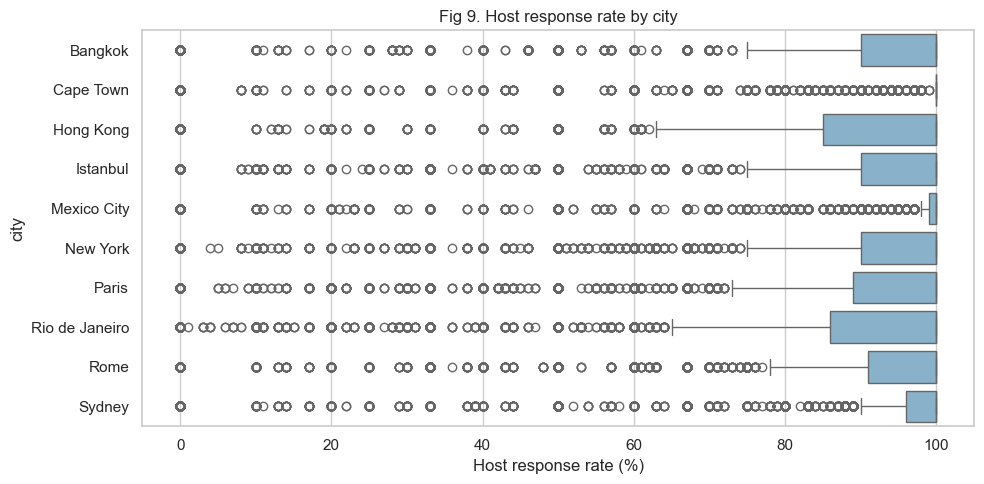

In [29]:
# ---- Assumption-check figure for H4 and overall summary figure ----
plt.figure(figsize=(10, 5))  # canvas
order = h4_table.sort_values("median").index  # order cities by median response rate
sns.boxplot(data=hr, x="response_rate", y="city", order=order, color="#7fb3d5")  # distribution per city
plt.xlabel("Host response rate (%)")  # axis label
plt.title("Fig 9. Host response rate by city")  # title
savefig("fig9_response_rate_by_city.png")  # save and show

## 8. Limitations (Task 4)

| Limitation | Effect on findings | How it was handled |
|---|---|---|
| **Missing listing attributes** (`bedrooms`, `district`, ratings, host rates) | Smaller n; possible bias if missingness is systematic | Complete-case per test, missingness reported (Fig 8), no imputation |
| **Currency differences** (no currency field) | Raw prices not comparable across cities | All price tests run **within city**; no cross-city price ranking or pooling |
| **Unequal listing counts** | Large cities give highly "significant" results from trivial effects; small cities have low power | Effect sizes and CIs reported; `MIN_GROUP_N` enforced; Holm correction |
| **Duplicate `review_id`** | Using `review_id` alone as a key would mis-count | Pair (`listing_id`, `review_id`) validated as unique; counts use row counts per listing |
| **Different review activity levels** | Old listings accumulate reviews; new ones have none or unstable ratings | Analysis restricted to listings with records; association not interpreted as quality |
| **Missing district information** | Neighbourhood-level comparisons unreliable | District not used as a predictor |
| **Extreme prices** | Can distort means and parametric tests | Flagged (3×IQR on log price), rank-based tests, sensitivity analysis without extremes |
| **No booking or occupancy data** | Prices are asking prices, not revenue; popularity unobservable | No revenue, occupancy or demand claims are made |
| **No review text** | No sentiment analysis possible | Not attempted |
| **Association vs causation** | Observational snapshot with confounders (location, quality, season) | Language limited to "associated with"; no causal claims |

## 9. Findings and recommendations (Task 5)

In [30]:
# ---- Auto-generate findings from the computed results (no numbers are typed by hand) ----
lines = []  # collects finding sentences

n_cities_tested = len(h1)  # cities included in H1
n_sig_h1 = int(h1["significant"].sum())  # cities where room type matters after Holm correction
med_or_large = int(h1["effect_size_label"].isin(["medium", "large"]).sum())  # cities with practically meaningful effect
lines.append(f"F1. Room type: price differed by room type (Holm-adjusted p < {ALPHA}) in {n_sig_h1} of {n_cities_tested} cities; "
             f"the effect was medium or large in {med_or_large} cities.")  # H1 finding

acc = h2[h2["predictor"] == "accommodates"]  # capacity results
lines.append(f"F2. Capacity: Spearman rho between accommodates and price ranged {acc['rho'].min():.2f} to {acc['rho'].max():.2f} "
             f"(median {acc['rho'].median():.2f}); significant in {int(acc['significant'].sum())} of {len(acc)} cities.")  # H2 finding

bed = h2[h2["predictor"] == "bedrooms"]  # bedroom results
if len(bed):  # only if bedrooms could be tested
    lines.append(f"F3. Bedrooms: rho ranged {bed['rho'].min():.2f} to {bed['rho'].max():.2f} (n reduced by missing bedrooms).")  # bedrooms finding

pooled_row = h3.iloc[0]  # pooled review result
lines.append(f"F4. Reviews vs rating: pooled rho = {pooled_row['rho']:.3f} (95% CI {pooled_row['ci_low']:.3f} to {pooled_row['ci_high']:.3f}, "
             f"n = {int(pooled_row['n']):,}); this is a {pooled_row['strength']} association between review activity and aggregate rating (not satisfaction).")  # H3 finding

verdict = "differed" if p4 < ALPHA else "did not differ detectably"  # wording follows the test result
lines.append(f"F5. Host response: response rates {verdict} across cities (Kruskal-Wallis H = {H4:,.1f}, p = {p4:.3g}, epsilon-squared = {max(eps4, 0):.3f}); "
             f"missingness differs by city, so comparisons apply only to hosts with a recorded rate.")  # H4 finding

top_city = city_counts.index[0]  # largest market
lines.append(f"F6. Market size: {top_city} has the most listings ({city_counts.iloc[0]:,}); the smallest market has {city_counts.iloc[-1]:,}, "
             f"so city comparisons are unbalanced.")  # distribution finding

findings = pd.Series(lines, name="finding")  # tidy container
findings.to_csv(os.path.join(OUT_DIR, "findings.csv"), index=False)  # save
for sentence in lines:  # print each finding
    print(sentence, "\n")  # blank line for readability

F1. Room type: price differed by room type (Holm-adjusted p < 0.05) in 10 of 10 cities; the effect was medium or large in 9 cities. 

F2. Capacity: Spearman rho between accommodates and price ranged 0.31 to 0.68 (median 0.52); significant in 10 of 10 cities. 

F3. Bedrooms: rho ranged 0.37 to 0.67 (n reduced by missing bedrooms). 

F4. Reviews vs rating: pooled rho = -0.205 (95% CI -0.209 to -0.200, n = 188,306); this is a weak association between review activity and aggregate rating (not satisfaction). 

F5. Host response: response rates differed across cities (Kruskal-Wallis H = 1,967.8, p = 0, epsilon-squared = 0.013); missingness differs by city, so comparisons apply only to hosts with a recorded rate. 

F6. Market size: Paris has the most listings (64,690); the smallest market has 7,087, so city comparisons are unbalanced. 



### Interpretation of the results on the supplied data
- **Room type (H1):** price differs by room type in all 10 cities; the effect is large in 8 cities, medium in Paris and small in Bangkok (ε² = 0.05), where hotel rooms and entire places have similar median prices. Entire places cost more than private and shared rooms in every city, and shared rooms are the cheapest everywhere. Hotel rooms are not consistently the most expensive.
- **Capacity (H2):** positive, strong or moderate associations in all 10 cities (accommodates ρ from 0.31 in Bangkok to 0.68 in Sydney; bedrooms 0.37 to 0.67). Removing extreme prices changed ρ by at most 0.002.
- **Reviews vs rating (H3):** weak negative association (pooled ρ ≈ −0.20); negligible in Hong Kong, where the adjusted p is borderline (≈ 0.046).
- **Host response (H4):** response rates differ across cities, but the effect is small (ε² ≈ 0.013) and every city has median 100%. Response-rate missingness ranges from 16% (Hong Kong) to 64% (Paris), so this comparison covers only hosts with a recorded rate.
- **Review activity over time (Fig 6):** monthly review records peak in October 2019 and fall sharply from March 2020, consistent with the pandemic period. The records cannot show why, and they are not occupancy.
- **Statistical vs practical significance:** with 7,000 to 65,000 listings per city almost every test gives p < 0.001, so conclusions rest on effect sizes and confidence intervals.

### Recommendations

| # | Recommendation | Evidence (see tables) | How to evaluate usefulness |
|---|---|---|---|
| R1 | Compare and benchmark prices **only within a city and within a room type**; never rank cities by raw price. | No currency field; H1 shows room-type effects within cities | A benchmarking report that stratifies by city × room type reproduces within-segment medians in `price_summary_by_city_local_currency.csv` |
| R2 | Use capacity (accommodates, bedrooms) as a **primary segmentation variable** for price comparisons wherever H2 shows a moderate or strong association; treat weak-association cities with caution. | H2 correlations and CIs per city | Check that segmented medians are more homogeneous than unsegmented ones (lower within-segment IQR) |
| R3 | Report review counts as **activity**, never as satisfaction, and show the share of listings without ratings next to any rating chart. | H3, Fig 5, Fig 8 | Reviewers confirm no dashboard label equates review volume with quality |
| R4 | Before any host-performance comparison across cities, report **missingness of response rate by city** alongside the metric. | H4 table (`pct_missing_in_city`) | Stakeholders can see the denominator for every host KPI |
| R5 | To answer revenue or demand questions, **acquire booking/occupancy data and a currency field**, and document dated exchange rates if converting. | Section 8 limitations | A data-request ticket exists and the next analysis can compute occupancy-based metrics |

*Replace the generic wording of any recommendation with the specific figures printed above when you write the final report.*

### Contribution to the overall project and honest integration statement
The cleaned listing table, per-listing review counts, per-city price summaries and the data-quality log are saved in `outputs/` so that the dashboard (Track A), the price model (Track C) and the assistant (Track D) **could** consume the same validated definitions (listing count = unique `listing_id`; advertised price = local-currency `price` > 0; review count = number of review rows per `listing_id`). **This notebook has not consumed the work of other tracks, and no integration is claimed beyond shared definitions.**

## 10. Reproducibility record

In [31]:
print("Python :", platform.python_version())  # interpreter version
print("pandas :", pd.__version__)  # pandas version
print("numpy  :", np.__version__)  # numpy version
print("scipy  :", scipy.__version__)  # scipy version
print("seaborn:", sns.__version__)  # seaborn version
print("Seed   :", SEED)  # random seed
print("Outputs written to:", os.path.abspath(OUT_DIR))  # where results are stored
print(sorted(os.listdir(OUT_DIR)))  # list of files produced

listings.drop(columns=[c for c in ["district"] if c in listings.columns]).to_csv(
    os.path.join(OUT_DIR, "listings_clean_no_identifiers.csv"), index=False)  # cleaned listing table (no names or host ids)

Python : 3.13.9
pandas : 2.3.3
numpy  : 2.3.5
scipy  : 1.16.3
seaborn: 0.13.2
Seed   : 42
Outputs written to: C:\Users\Tarfa_Jr\outputs
['H1_room_type_price_by_city.csv', 'H2_capacity_price_by_city.csv', 'H3_reviews_vs_rating.csv', 'H4_response_rate_by_city.csv', 'cleaning_log.csv', 'data_quality_summary.csv', 'figures', 'findings.csv', 'listings_clean_no_identifiers.csv', 'listings_per_city.csv', 'price_summary_by_city_local_currency.csv', 'reviews_per_month.csv', 'top10_property_types.csv']
